[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/05-iris-regressao-logistica.ipynb)

# Iris com regressao logistica

Tres especies de Iris (setosa, versicolor e virginica) medidas por Edgar Anderson e tornadas classicas por Fisher em 1936. O arquivo vem do `load_iris` do scikit-learn, que redistribui a tabela da UCI. Este caderno usa so o comprimento e a largura da petala, em centimetros, para a fronteira caber num plano.

Ha duas etapas. Primeiro, versicolor contra virginica, com a sigmoide. Depois as tres especies, com a softmax. Setosa, no plano da petala, fica quase separada das outras duas; versicolor e virginica se encostam.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Num jardim, duas petalas bastam para muita gente separar as tres Iris de vista: a setosa e a miuda, e as outras duas disputam o canto das petalas grandes. A regressao logistica faz a versao numerica dessa cerca. Cada flor ganha um escore, o escore vira probabilidade, e a cerca e o lugar em que a probabilidade cruza a metade. Com tres especies ha tres cercas, e cada ponto do plano fica com a cor da especie mais provavel.


## 2) Fundamentação matemática

A regressao logistica desenha um escore linear e o espreme numa probabilidade. O escore e

$$
z = w^{\top} x + b
$$

- $x$ e o vetor de atributos da amostra.
- $w$ e o vetor de pesos, um por atributo.
- $b$ e o vies, o escore quando todos os atributos valem zero.
- $z$ e o logaritmo da chance, o log-odds: $\log \frac{p}{1-p} = z$.

A sigmoide converte $z$ na probabilidade da classe positiva:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Se $z = 0$, $\sigma(z) = 0{,}5$.
- Se $z$ cresce, $\sigma(z)$ sobe em direcao a 1, sem nunca passar de 1.
- Se $z$ cai, $\sigma(z)$ desce em direcao a 0.
- A derivada $\sigma(z)\,(1-\sigma(z))$ e a que aparece no gradiente.

Com mais de duas classes, cada classe tem seu escore $z_k$ e a softmax divide as exponenciais:

$$
P(y = k \mid x) = \frac{e^{z_k}}{\sum_{c=1}^{K} e^{z_c}}
$$

- $z_k = w_k^{\top} x + b_k$ e o escore da classe $k$.
- $K$ e o numero de classes.
- O denominador faz as $K$ probabilidades somarem 1.
- Subtrair $\max_c z_c$ antes da exponencial nao muda o resultado e evita estouro numerico.

O treino minimiza a entropia cruzada, a surpresa media de ter previsto pouco a classe verdadeira, mais uma penalidade L2 so nos pesos:

$$
J(w, b) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log \hat{p}_i + (1-y_i)\log(1-\hat{p}_i)\Big] + \frac{\lambda}{2}\|w\|^2
$$

- $n$ e o numero de amostras de treino.
- $y_i$ vale 1 na classe positiva e 0 na negativa.
- $\hat{p}_i = \sigma(w^{\top} x_i + b)$.
- $\lambda$ e o argumento `l2` do codigo. O vies $b$ nao entra em $\|w\|^2$: deslocar a fronteira nao deve ser punido do mesmo jeito que um peso enorme.
- No caso multiclasse, $y_i \log \hat{p}_i$ vira o log da probabilidade da classe correta.

A descida de gradiente anda no sentido em que $J$ diminui. Para a perda media acima, com a classe positiva codificada como 1:

$$
\frac{\partial J}{\partial w} = \frac{1}{n} X^{\top}(\hat{p} - y) + \lambda w, \qquad \frac{\partial J}{\partial b} = \frac{1}{n}\sum_{i=1}^{n}(\hat{p}_i - y_i)
$$

- $\hat{p} - y$ e o erro de cada amostra. Positivo quando o modelo exagerou a classe 1.
- $X^{\top}(\hat{p}-y)/n$ aponta quais atributos empurraram esse erro.
- $\lambda w$ encolhe os pesos em direcao a zero.
- O passo e $w \leftarrow w - \eta \, \partial J/\partial w$, e $\eta$ e o `learning_rate`.

O `C` do scikit-learn penaliza a soma dos erros, nao a media. Com $C = 1$, o $\lambda$ equivalente nesta media e $1/n$. E o valor usado nos cadernos para a comparacao ser justa. O otimizador deles (lbfgs) nao e o nosso passo fixo, entao os pesos nao precisam coincidir casa decimal; a qualidade no teste e que precisa ficar perto.


## 3) Visualização

Cada ponto e uma flor. A cor e a especie. Ainda nao ha modelo nesta figura: e o plano em que a fronteira vai ser desenhada.


flores 150 especies [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


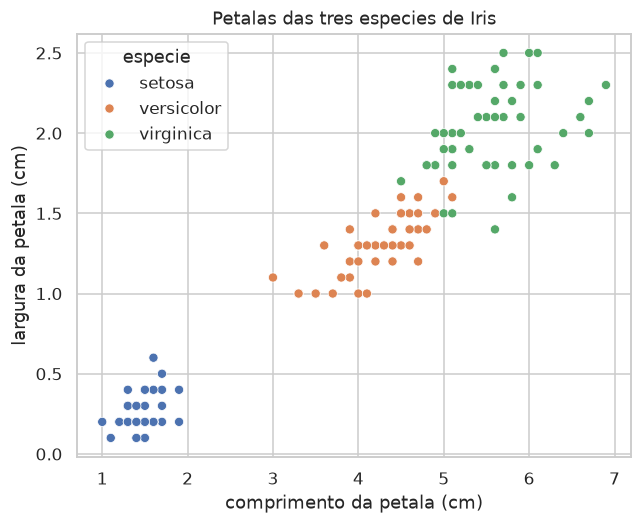

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
nomes = list(iris.target_names)
X = iris.data[:, 2:4]
y = iris.target
df = pd.DataFrame(X, columns=["comprimento_petala", "largura_petala"])
df["especie"] = [nomes[i] for i in y]
print("flores", len(df), "especies", nomes)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(data=df, x="comprimento_petala", y="largura_petala", hue="especie", ax=ax)
ax.set_title("Petalas das tres especies de Iris")
ax.set_xlabel("comprimento da petala (cm)")
ax.set_ylabel("largura da petala (cm)")
plt.show()

# Binario: versicolor (1) contra virginica (2). A setosa fica de fora desta cerca.
mascara = y > 0
X_bin = X[mascara]
y_bin = (y[mascara] == 2).astype(int)
from sklearn.model_selection import train_test_split

X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(X_bin, y_bin, test_size=0.3, random_state=0, stratify=y_bin)
X_tr_b_p, X_te_b_p, media_b, desvio_b = padronizar(X_tr_b, X_te_b)


## 4) Implementação do zero

O primeiro ajuste e binario: classe 1 = virginica, classe 0 = versicolor. O segundo e softmax nas tres especies, treinado em outro recorte. Os dois usam $\lambda = 1/n$, o equivalente a `C=1` do scikit-learn na perda media. Atributos padronizados com media e desvio do treino: sem isso o passo fixo sofre com centimetros de escalas parecidas, mas ainda assim diferentes.


perda inicial e final, binario 0.6931 0.2269


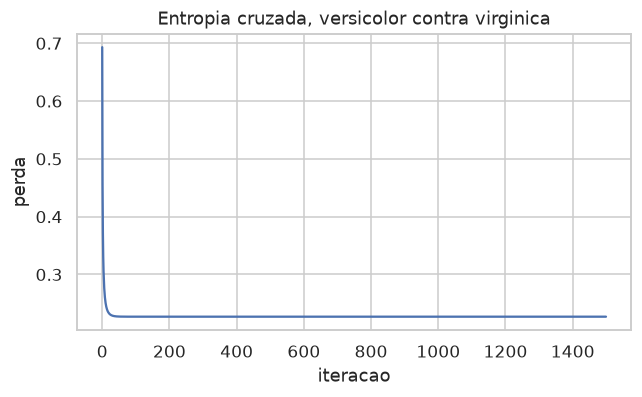

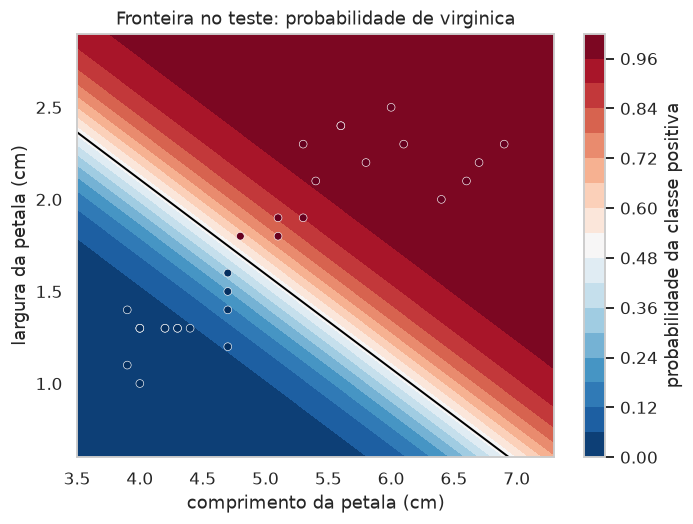

classes [np.int64(0), np.int64(1), np.int64(2)] perda final 0.2738


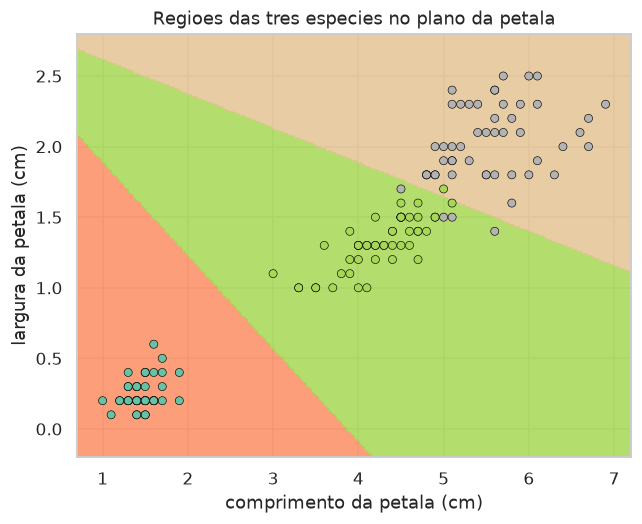

In [3]:
from mlalgos import LogisticRegression

l2_b = 1.0 / len(X_tr_b_p)
modelo_bin = LogisticRegression(learning_rate=1.0, n_iterations=1500, l2=l2_b)
modelo_bin.fit(X_tr_b_p, y_tr_b)
print("perda inicial e final, binario", round(modelo_bin.loss_history_[0], 4), round(modelo_bin.loss_history_[-1], 4))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(modelo_bin.loss_history_)
ax.set_xlabel("iteracao")
ax.set_ylabel("perda")
ax.set_title("Entropia cruzada, versicolor contra virginica")
plt.show()
xx, yy = np.meshgrid(
    np.linspace(X_te_b[:, 0].min() - 0.4, X_te_b[:, 0].max() + 0.4, 220),
    np.linspace(X_te_b[:, 1].min() - 0.4, X_te_b[:, 1].max() + 0.4, 220),
)
grade = np.column_stack([xx.ravel(), yy.ravel()])
grade_p = (grade - media_b) / desvio_b
probabilidade = modelo_bin.predict_proba(grade_p)[:, 1].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 5))
mapa = ax.contourf(xx, yy, probabilidade, levels=16, cmap="RdBu_r")
ax.contour(xx, yy, probabilidade, levels=[0.5], colors="black", linewidths=1.3)
ax.scatter(X_te_b[:, 0], X_te_b[:, 1], c=y_te_b, cmap="RdBu_r", edgecolor="white", linewidth=0.4, s=26)
fig.colorbar(mapa, ax=ax, label="probabilidade da classe positiva")
ax.set_xlabel('comprimento da petala (cm)')
ax.set_ylabel('largura da petala (cm)')
ax.set_title('Fronteira no teste: probabilidade de virginica')
plt.show()

X_tr, X_te, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
X_treino_p, X_teste_p, media, desvio = padronizar(X_tr, X_te)
l2 = 1.0 / len(X_treino_p)
modelo = LogisticRegression(learning_rate=0.8, n_iterations=1500, l2=l2)
modelo.fit(X_treino_p, y_treino)
print("classes", list(modelo.classes_), "perda final", round(modelo.loss_history_[-1], 4))

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 220),
    np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 220),
)
grade = np.column_stack([xx.ravel(), yy.ravel()])
grade_p = (grade - media) / desvio
previsto = modelo.predict(grade_p).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.contourf(xx, yy, previsto, levels=np.arange(-0.5, 3.5, 1), cmap="Set2", alpha=0.85)
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="Set2", edgecolor="black", linewidth=0.4, s=28)
ax.set_xlabel("comprimento da petala (cm)")
ax.set_ylabel("largura da petala (cm)")
ax.set_title("Regioes das tres especies no plano da petala")
plt.show()


## 5) Implementação com scikit-learn

Os dois recebem a mesma matriz padronizada das tres especies. A concordancia nao precisa ser de 100% porque o otimizador e outro; o que se cobra e a acuracia ficar colada.


In [4]:
from sklearn.linear_model import LogisticRegression as SkLogistic

sk = SkLogistic(C=1.0, max_iter=500).fit(X_treino_p, y_treino)
print("acuracia nossa no teste", float(modelo.score(X_teste_p, y_teste)))
print("acuracia sklearn no teste", float(sk.score(X_teste_p, y_teste)))
print("concordancia", float(np.mean(modelo.predict(X_teste_p) == sk.predict(X_teste_p))))


acuracia nossa no teste 0.9777777777777777
acuracia sklearn no teste 0.9777777777777777
concordancia 1.0


## 6) Avaliação

Os numeros sao do modelo softmax com as tres especies, no recorte de teste. A ROC-AUC e macro, um-contra-o-resto. Na matriz, 0 e setosa, 1 e versicolor e 2 e virginica, a ordem do `load_iris`.


acuracia 0.978 | baseline da classe majoritaria 0.333
precisao macro 0.979 | revocacao macro 0.978 | f1 macro 0.978 | roc_auc macro 1.000
RESUMO_METRICAS {"modelo": "softmax_iris_petalas", "acuracia": 0.9777777777777777, "precisao_macro": 0.9791666666666666, "revocacao_macro": 0.9777777777777779, "f1_macro": 0.9777530589543938, "roc_auc_macro": 1.0, "baseline_majoritaria": 0.3333333333333333}


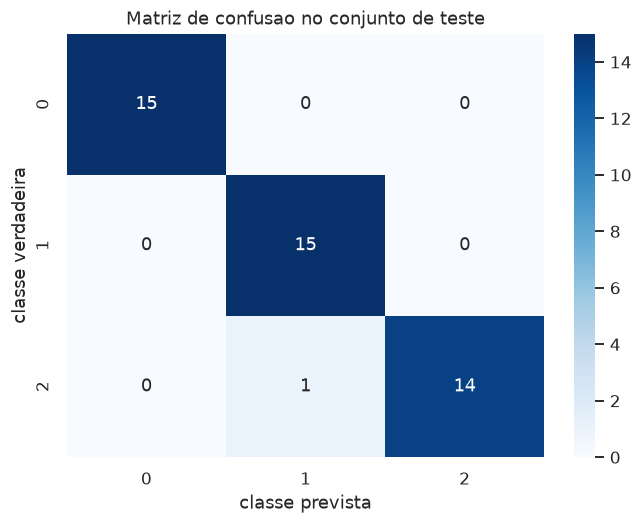

In [5]:
from mlalgos.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = modelo.predict(X_teste_p)
y_proba = modelo.predict_proba(X_teste_p)
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, average="macro")
revocacao = recall_score(y_teste, y_previsto, average="macro")
f1 = f1_score(y_teste, y_previsto, average="macro")
auc = roc_auc_score(y_teste, y_proba, average="macro")
frequencias = pd.Series(y_teste).value_counts(normalize=True)
baseline = float(frequencias.max())
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao macro {precisao:.3f} | revocacao macro {revocacao:.3f} | f1 macro {f1:.3f} | roc_auc macro {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'softmax_iris_petalas',
    "acuracia": acuracia,
    "precisao_macro": precisao,
    "revocacao_macro": revocacao,
    "f1_macro": f1,
    "roc_auc_macro": auc,
    "baseline_majoritaria": baseline,
}))

ordem = list(modelo.classes_)
cm = confusion_matrix(y_teste, y_previsto, labels=ordem)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ordem, yticklabels=ordem, ax=ax)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()


## 7) Desafios

1. Inclua o comprimento e a largura da sepala e compare o F1 macro. A fronteira deixa de caber no plano: como voce mostraria o erro mesmo assim?
2. Treine so setosa contra o resto (classe positiva = setosa). Por que a perda cai mais depressa do que na disputa versicolor/virginica?
3. Aumente `l2` para 1. O que acontece com a fronteira e com os pesos?
